# MMA3001 Project
## Project title: Formula 1 Predicted Next Lap Time

### Project owner: Liew Chong Jun
### Project Supervisor: Dr. Yeoh Chin Vern


# Formula 1 data and model laboratory
**Start here:** run cells from top to bottom using the project's Python kernel. First downloads require internet; subsequent runs reuse the FastF1 cache.

This is a **Phase 1 feasibility pilot**, not a final approved topic or a trained CNN. It explores Bahrain 2024, audits the data and gives you a reusable baseline-training workspace. The final section stays off until your topic is approved and you configure separate race weekends.

**Engineering motivation:** support race-pace analysis by estimating the next lap's duration from information already observed. This cannot measure tyre wear, predict incidents, or produce a team's optimal strategy.

1. Settings and environment → 2. Real data → 3. Quality audit → 4. Visual analysis → 5. Numerical exploration → 6. Optional training → 7. Reflection.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from importlib.metadata import version
from mma3001_f1.data import collect_session, plot_pilot
from mma3001_f1.modeling import make_examples, split_weekends, train_baseline, evaluate, score

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Launch Jupyter from the Project folder."
print("Python:", sys.executable)
display(pd.Series({p: version(p) for p in ["fastf1", "pandas", "numpy", "scikit-learn"]}, name="version"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: C:\Users\Admin\Documents\MMA3001\Project\.venv-project\Scripts\python.exe


fastf1          3.8.3
pandas          2.3.3
numpy           2.5.3
scikit-learn    1.9.1
Name: version, dtype: object

## 1 · Your control panel
Change these values, then rerun from here. A history of 3 means three consecutive completed laps from the same driver and stint. `RIDGE_ALPHAS` controls coefficient regularisation: larger values discourage large fitted coefficients. This regression has no epochs, batch size or learning rate because it uses a direct numerical solver, not neural-network training.

Keep the explored Bahrain pilot in development/training data. Never use it as an untouched final test race. Choose additional races and record their roles **before** inspecting their outcomes.

In [ ]:
YEAR, EVENT, SESSION = 2024, "Bahrain", "R"
DRIVERS = ("VER", "LEC")
HISTORY_LAPS = 3
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0]
TOPIC_APPROVED = False  # Change only after actual teaching-team confirmation.
RUN_TRAINING = False
RUN_FINAL_TEST = False  # Enable only after validation choices are frozen.
# Tuples are (year, event, session). All sessions in a weekend must share one role.
TRAIN_RACES = [(2024, "Bahrain", "R")]
VALIDATION_RACES = []
TEST_RACES = []

## 2 · Retrieve real observations
The source export is preserved in `data/raw`; converted fields and quality flags go to `data/processed`. Durations use **total seconds**, so minutes and days are handled correctly. Missing targets remain missing. Download failures raise an error; no invented sample race is substituted.

Weather is exported if available with its original session timestamps. It is not joined or used for prediction. A future weather join must use the last observation available at prediction time, with a justified maximum age.

In [3]:
laps, quality, manifest = collect_session(ROOT, YEAR, EVENT, SESSION)
display(pd.Series(manifest))
display(laps[["SourceRow", "Driver", "LapNumber", "LapTimeSeconds", "Compound", "TyreLife", "Stint", "Eligible"]].head(12))

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data


req            INFO 	Using cached data for lap_count


...

req            INFO 	Using cached data for weather_data


req            INFO 	Using cached data for race_control_messages


core           INFO 	Finished loading data for 20 drivers: ['1', '11', '55', '16', '63', '4', '44', '81', '14', '18', '24', '20', '3', '22', '23', '27', '31', '10', '77', '2']


source                                       FastF1 / F1 timing data
session_id                                                 2024-01-R
year                                                            2024
event                                             Bahrain Grand Prix
session                                                            R
retrieved_utc                       2026-09-13T09:15:17.381204+00:00
versions           {'fastf1': '3.8.3', 'pandas': '2.3.3', 'numpy'...
rows                                                            1129
weather_rows                                                     157
transformations    Copy all rows; SourceRow zero-based; timedelta...
quality_report                        reports/2024-01-R_quality.json
dtype: object

,SourceRow,Driver,LapNumber,LapTimeSeconds,Compound,TyreLife,Stint,Eligible
0,0,VER,1.0,97.284,SOFT,4.0,1.0,False
1,1,VER,2.0,96.296,SOFT,5.0,1.0,True
2,2,VER,3.0,96.753,SOFT,6.0,1.0,True
3,3,VER,4.0,96.647,SOFT,7.0,1.0,True
4,4,VER,5.0,97.173,SOFT,8.0,1.0,True
5,5,VER,6.0,97.092,SOFT,9.0,1.0,True
6,6,VER,7.0,97.038,SOFT,10.0,1.0,True
7,7,VER,8.0,97.024,SOFT,11.0,1.0,True
8,8,VER,9.0,97.229,SOFT,12.0,1.0,True
9,9,VER,10.0,96.960,SOFT,13.0,1.0,False


## 3 · Audit before excluding
Raw rows are never dropped. The proposed clean population excludes missing/nonpositive times, invalid or duplicate identifiers, pit laps, non-green running, inaccurate/deleted/generated records, unknown quality and unsupported tyre context. Slow laps are **not** excluded by an arbitrary time cutoff. Counts below show both overlapping flags and each rule's additional effect.

Missing `PitInTime`/`PitOutTime` values normally mean no pit event; an entirely absent source column is instead treated as unknown. Provider quality flags are useful checks, not independent ground truth.

In [4]:
display(pd.Series({k: quality[k] for k in ["rows", "drivers", "eligible_rows", "unavailable_quality_fields"]}))
display(pd.DataFrame(quality["exclusion_waterfall"]))
display(pd.Series(quality["missing"], name="missing_count").sort_values(ascending=False).to_frame())
display(pd.DataFrame.from_dict(quality["lap_coverage"], orient="index"))
display(pd.Series(quality["nonpositive_durations"], name="nonpositive_duration_count"))
clean = laps.loc[laps.Eligible].copy()
display(clean.groupby("Compound").LapTimeSeconds.agg(["count", "median", "mean", "std"]))

rows                          1129
drivers                         20
eligible_rows                  988
unavailable_quality_fields      []
dtype: object

,rule,flagged,newly_excluded,remaining
0,FlagDuplicate,0,0,1129
1,FlagInvalidID,0,0,1129
2,FlagInvalidTime,2,2,1127
3,FlagPit,86,84,1043
4,FlagInterrupted,42,37,1006
5,FlagInaccurate,105,0,1006
6,FlagDeleted,20,18,988
7,FlagGenerated,0,0,988
8,FlagUnknownQuality,0,0,988
9,FlagUnsupportedTyre,0,0,988


,missing_count
LapStartDate,1129
PitOutTime,1086
PitInTime,1086
SpeedFL,43
Sector1SessionTime,22
Sector1Time,21
Sector1TimeSeconds,21
LapTime,2
LapTimeSeconds,2
DriverNumber,0


,min,max,count,nunique
ALB,1.0,56.0,56,56
ALO,1.0,57.0,57,57
BOT,1.0,56.0,56,56
GAS,1.0,56.0,56,56
HAM,1.0,57.0,57,57
HUL,1.0,56.0,56,56
LEC,1.0,57.0,57,57
MAG,1.0,56.0,56,56
NOR,1.0,57.0,57,57
OCO,1.0,56.0,56,56


LapTimeSeconds        0
Sector1TimeSeconds    0
Sector2TimeSeconds    0
Sector3TimeSeconds    0
Name: nonpositive_duration_count, dtype: int64

,count,median,mean,std
Compound,,,,
HARD,719,96.756,96.768947,1.066183
SOFT,269,97.862,97.305394,1.605334


## 4 · Race pace and tyre-stint analysis
The first chart includes all recorded laps and marks records outside the proposed population. The second shows compound and stint timing across drivers. Pace changes can also reflect fuel load, traffic, weather and driver management. Neither plot isolates a causal tyre effect; tyre age is not remaining tyre life.

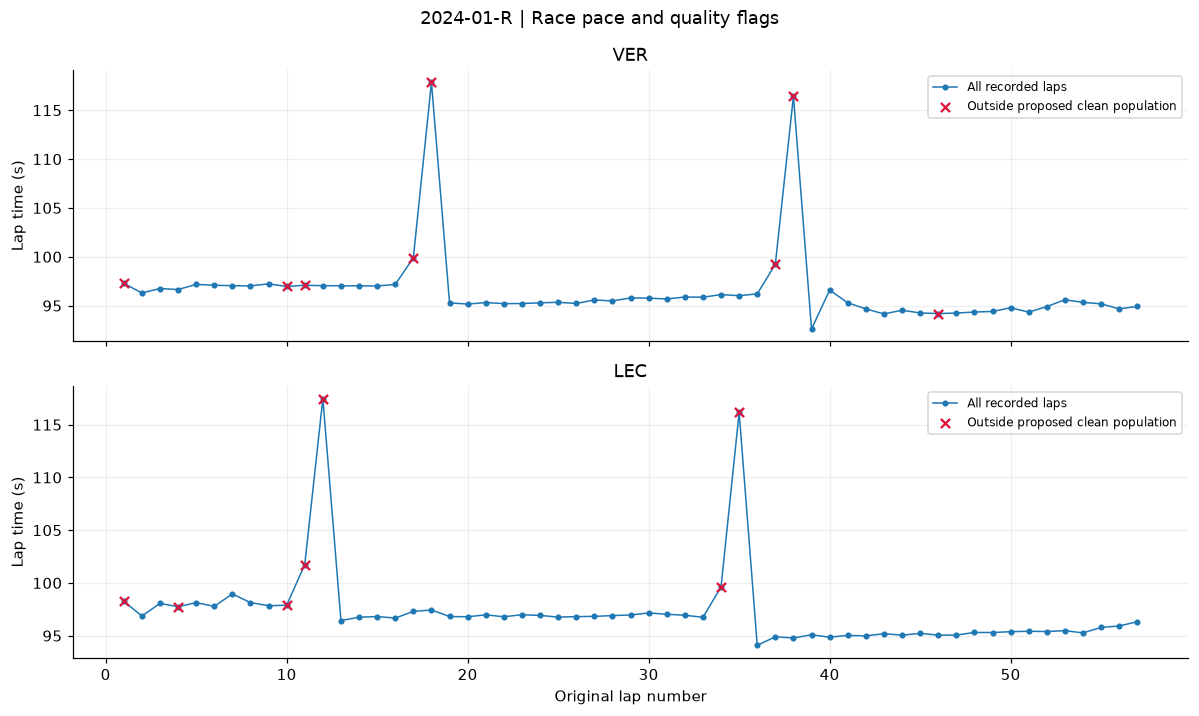

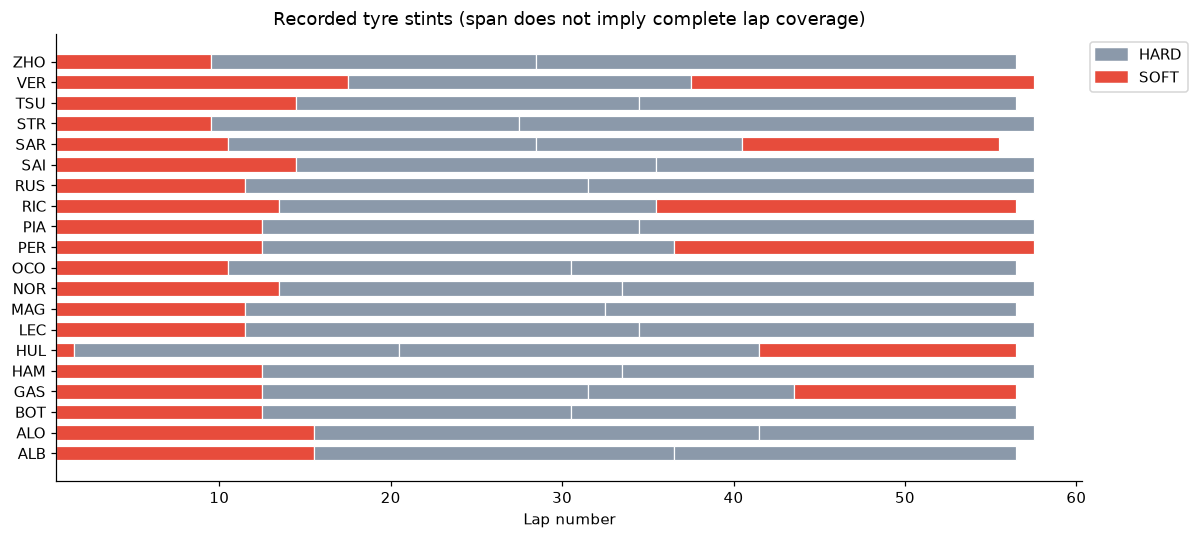

laps  first_lap  last_lap  median_seconds  \
Driver Stint Compound                                              
ALB    1.0   SOFT        12        2.0      14.0         98.7415   
       2.0   HARD        19       17.0      35.0         97.9680   
       3.0   HARD        17       38.0      56.0         96.1290   
ALO    1.0   SOFT        12        2.0      14.0         98.5485   
       2.0   HARD        24       17.0      40.0         97.2290   
...                     ...        ...       ...             ...   
VER    2.0   HARD        18       19.0      36.0         95.5290   
       3.0   SOFT        18       39.0      57.0         94.6690   
ZHO    1.0   SOFT         7        2.0       8.0         98.7980   
       2.0   HARD        17       11.0      27.0         97.7490   
       3.0   HARD        27       30.0      56.0         96.7410   

                       spread_seconds  
Driver Stint Compound                  
ALB    1.0   SOFT            0.194852  
       2.0   HARD            0.254740  
       3.0   HARD            0.588524  
ALO    1.0   SOFT            0.470923  
       2.0   HARD            0.377452  
...                               ...  
VER    2.0   HARD            0.346513  
       3.0   SOFT            0.801603  
ZHO    1.0   SOFT            0.490029  
       2.0   HARD            0.462140  
       3.0   HARD            0.565146  

[62 rows x 5 columns]

In [5]:
figures = plot_pilot(laps, ROOT / "results/figures" / manifest["session_id"], DRIVERS)
plt.show()
summary = clean.groupby(["Driver", "Stint", "Compound"]).agg(
    laps=("LapNumber", "count"), first_lap=("LapNumber", "min"), last_lap=("LapNumber", "max"),
    median_seconds=("LapTimeSeconds", "median"), spread_seconds=("LapTimeSeconds", "std"))
summary.to_csv(ROOT / "results/tables" / f"{manifest['session_id']}_stints.csv")
display(summary)

## 5 · Numerical exploration: a straight-line fit
Least squares chooses the line with the smallest sum of squared residuals. `numpy.linalg.lstsq` solves the small system without explicitly inverting a matrix. We centre tyre age to improve conditioning. The slope is an **association in seconds per tyre lap**, not a physical wear rate. This within-stint demonstration is not withheld-data validation and does not select the final method.

VER, stint 1.0: slope = 0.0315 s/tyre lap; matrix condition number = 4.59


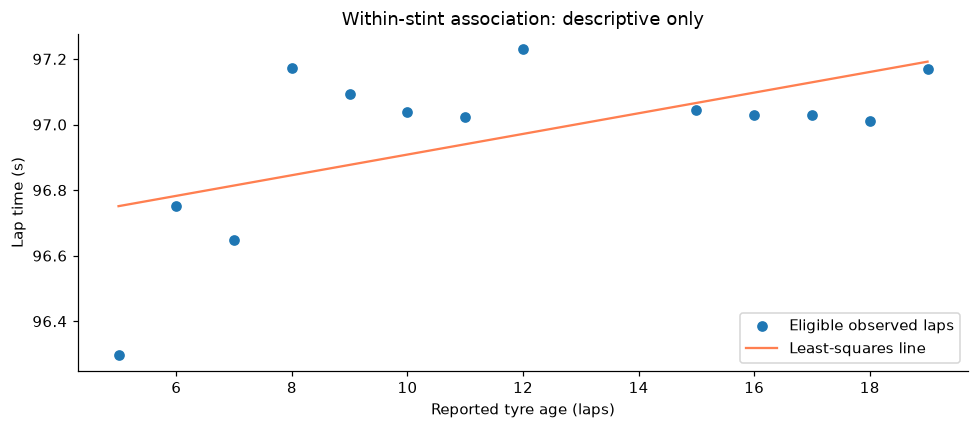

In [6]:
groups = [(key, g) for key,g in clean[clean.Driver.eq(DRIVERS[0])].groupby("Stint") if len(g) >= 5 and g.TyreLife.nunique() >= 2]
if groups:
    stint, sample = groups[0]
    x, y = sample.TyreLife.to_numpy(dtype=float), sample.LapTimeSeconds.to_numpy()
    A = np.column_stack([np.ones(len(x)), x-x.mean()])
    coef, _, rank, singular_values = np.linalg.lstsq(A, y, rcond=None)
    print(f"{DRIVERS[0]}, stint {stint}: slope = {coef[1]:.4f} s/tyre lap; matrix condition number = {np.linalg.cond(A):.2f}")
    order = np.argsort(x)
    plt.figure(figsize=(9,4))
    plt.scatter(x,y,label="Eligible observed laps")
    plt.plot(x[order],(A@coef)[order],label="Least-squares line",color="coral")
    plt.xlabel("Reported tyre age (laps)"); plt.ylabel("Lap time (s)")
    plt.title("Within-stint association: descriptive only"); plt.legend(); plt.tight_layout()
    plt.savefig(ROOT / "results/figures" / manifest["session_id"] / "stint_line.png", dpi=150)
    plt.show()
else:
    print("No stint has enough eligible observations for this demonstration.")

## 6 · Prepare ordered next-lap examples
Prediction time is the end of the current lap. Inputs contain only previous completed lap times, current tyre age and current lap number. The target is next-lap seconds. Windows cannot cross drivers, missing lap numbers, excluded laps or stint boundaries.

We retrospectively require the target lap to be clean too. Consequently, the evaluation answers **how accurate predictions are during uninterrupted dry running**, not whether the model knows future incidents. Circuit/driver effects remain a limitation of this small baseline.

In [7]:
pilot_examples = make_examples(laps, HISTORY_LAPS)
print("Pilot training-example candidates:", len(pilot_examples))
display(pilot_examples.head())

Pilot training-example candidates: 744


,SessionID,Driver,TargetLap,EventDate,TargetSeconds,CurrentTyreLife,CurrentLap,Lag1,Lag2,Lag3
0,2024-01-R,ALB,5.0,2024-03-02 00:00:00,98.509,4.0,4.0,98.422,98.507,98.826
1,2024-01-R,ALB,6.0,2024-03-02 00:00:00,98.575,5.0,5.0,98.509,98.422,98.507
2,2024-01-R,ALB,7.0,2024-03-02 00:00:00,98.971,6.0,6.0,98.575,98.509,98.422
3,2024-01-R,ALB,8.0,2024-03-02 00:00:00,98.660,7.0,7.0,98.971,98.575,98.509
4,2024-01-R,ALB,9.0,2024-03-02 00:00:00,98.652,8.0,8.0,98.660,98.971,98.575


### Optional training and parameter sensitivity
After topic approval, populate the three race lists. The code rejects overlapping weekends and enforces training → validation → test chronology. Scaling is learned on training rows only. Validation compares ridge penalties on the same examples; the final test is not downloaded until you explicitly enable it.

The baseline predicts that the next lap equals the last lap. MAE is the typical absolute error; RMSE penalises large misses more heavily. Both use seconds. One validation and one test race are minimum software requirements, not evidence of broad generalisation. A CNN would need more races, a justified sequence architecture and a separate comparison; no deep-learning framework is installed here.

In [8]:
model = None
if RUN_TRAINING:
    if not TOPIC_APPROVED:
        raise ValueError("Record actual topic approval before substantial model development.")
    roles = [TRAIN_RACES, VALIDATION_RACES, TEST_RACES]
    if any(not r for r in roles):
        raise ValueError("Configure all three race roles before training.")
    # Resolve schedule IDs without loading test lap outcomes.
    import fastf1
    role_ids, role_dates = [], []
    for races in roles:
        sessions = [fastf1.get_session(*r) for r in races]
        role_ids.append([f"{r[0]}-{int(s.event.RoundNumber):02d}-{r[2]}" for r,s in zip(races,sessions)])
        role_dates.append([pd.Timestamp(s.event.EventDate) for s in sessions])
    weekend_sets = [{sid.rsplit("-",1)[0] for sid in ids} for ids in role_ids]
    if any(weekend_sets[i] & weekend_sets[j] for i in range(3) for j in range(i+1,3)):
        raise ValueError("Weekend roles overlap.")
    if not (max(role_dates[0]) < min(role_dates[1]) and max(role_dates[1]) < min(role_dates[2])):
        raise ValueError("Races must be ordered training, validation, test.")
    if manifest["session_id"].rsplit("-",1)[0] in weekend_sets[2]:
        raise ValueError("The explored pilot cannot be the final test.")
    def load_examples(races):
        return pd.concat([make_examples(collect_session(ROOT,*r)[0],HISTORY_LAPS) for r in races], ignore_index=True)
    train, validation = load_examples(TRAIN_RACES), load_examples(VALIDATION_RACES)
    for part,ids in zip([train,validation],role_ids[:2]):
        if part.empty or not set(ids).issubset(set(part.SessionID)):
            raise ValueError("A selected race has no eligible examples; inspect its quality report.")
    model, features, sensitivity = train_baseline(train, validation, RIDGE_ALPHAS)
    display(sensitivity)
    print("Previous-lap validation baseline:",score(validation.TargetSeconds,validation.Lag1))
    sensitivity.to_csv(ROOT / "results/tables/validation_alpha_sensitivity.csv", index=False)
    import joblib
    (ROOT / "results/models").mkdir(exist_ok=True)
    joblib.dump({"model":model,"features":features,"history":HISTORY_LAPS},ROOT / "results/models/ridge.joblib")
    settings = {"history":HISTORY_LAPS,"alphas":RIDGE_ALPHAS,"roles":role_ids,"selected_alpha":model[-1].alpha,
                "versions":{p:version(p) for p in ["numpy","pandas","scikit-learn","fastf1"]}}
    (ROOT / "results/models/training_settings.json").write_text(json.dumps(settings,indent=2))
else:
    print("Training scaffold ready. No model trained: topic and additional race roles remain open.")

Training scaffold ready. No model trained: topic and additional race roles remain open.


In [9]:
if RUN_FINAL_TEST:
    if model is None:
        raise ValueError("Run approved training first and freeze your validation choices.")
    final_test = load_examples(TEST_RACES)
    _,_,final_test = split_weekends(pd.concat([train,validation,final_test]),*role_ids)
    metrics, predictions = evaluate(model, features, final_test)
    display(metrics)
    predictions["absolute_error"] = abs(predictions.TargetSeconds-predictions.Ridge)
    display(predictions.groupby(["SessionID","Driver"]).absolute_error.agg(["count","mean","max"]))
    metrics.to_csv(ROOT / "results/tables/final_test_metrics.csv",index=False)
    predictions.to_csv(ROOT / "results/tables/final_test_predictions.csv",index=False)
else:
    print("Final test remains untouched. Do not tune settings after reviewing final-test scores.")

Final test remains untouched. Do not tune settings after reviewing final-test scores.


## 7 · What to record and discuss
- Which laps were excluded, and how does this change the question your model answers?
- What information was available at prediction time? Why would target-lap sectors leak the answer?
- Does the validation gain over the previous-lap baseline justify added complexity?
- How might circuit differences, fuel load, traffic and pit strategy affect results?
- Record actual approval, dataset choices, your interpretation and any corrections in `docs/decisions_and_ai.md`.

Read `docs/feasibility.md` for the proposed scope. Tests and their report are in `tests/` and `reports/`; generated function documentation is in `docs/html/`.

Sources: [FastF1 documentation](https://docs.fastf1.dev/), [FastF1 source](https://github.com/theOehrly/Fast-F1), [Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html). The local assessment summary and handoff guide the deliverables. Package licensing does not automatically cover underlying F1 data.